# 🏆 FahMai RAG — Intent-Aware Multi-Source Retrieval Pipeline
**รหัส:** 602044 — Atilak

---

## 🎯 โจทย์ (Motivation)

ร้านฟ้าใหม่มีฐานข้อมูล Markdown ครอบคลุม **สินค้า 110 รายการ + นโยบาย 5 ฉบับ + ข้อมูลร้าน 3 ชิ้น** รวม 118 ไฟล์  
คำถามแบบปรนัย 10 ตัวเลือก 100 ข้อ มีความซับซ้อนต่างกัน เช่น
- ถามสเปคตัวเดียว → ต้องหาตัวเลขให้ถูก
- เปรียบเทียบหลายสินค้า → ต้องดึงหลายไฟล์พร้อมกัน
- คำนวณราคา/แต้ม/ค่าส่ง → ต้องอ่านนโยบาย + คิดหลายขั้น
- คำถามยาวมาก → คำถามจริงฝังอยู่ท้ายย่อหน้า

**ปัญหาหลักที่แก้:** RAG แบบ one-size-fits-all ดึง context ผิดประเภท ทำให้ LLM ตอบผิด

---

## 🏗️ Pipeline Overview

```
คำถาม (Q)
    │
    ▼
┌─────────────────────────────────────────────────────┐
│  Cell 3 · Intent Classifier                         │
│  แยกเป็น 5 ประเภท → กำหนด TOP_K + search strategy  │
│                                                     │
│  SIMPLE_FACT   → TOP_K=5   (ถามสเปคสินค้าชิ้นเดียว) │
│  COMPARE       → TOP_K=8   (เปรียบเทียบ 2 สินค้า)   │
│  MULTI_PRODUCT → TOP_K=10  (3+ สินค้า / recommendation) │
│  POLICY_CALC   → TOP_K=10  (คำนวณ นโยบาย แต้ม ค่าส่ง) │
│  LONG_CONTEXT  → TOP_K=8   (คำถามยาว >200 ตัวอักษร)  │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
┌─────────────────────────────────────────────────────┐
│  Cell 3 · Query Builder                             │
│  dense_q  = extract core sentence (ตัดส่วนไม่เกี่ยว) │
│  bm25_q   = question + key spec terms จาก choices   │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
┌─────────────────────────────────────────────────────┐
│  Cell 6 · Smart Retrieval (Hybrid RRF)              │
│                                                     │
│  1. Dense retrieval  — BGE-M3 (1024-dim, Thai SOTA) │
│  2. BM25 retrieval   — Thai tokenizer (newmm)       │
│  3. RRF fusion       — เลือกรอดทั้ง semantic+keyword │
│  4. Force-retrieve   — product reverse index O(1)   │
│     ถ้า COMPARE/MULTI → guarantee ทุก product doc   │
│  5. Policy boost     — ถ้า POLICY_CALC ดัน policy ขึ้นก่อน │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
┌─────────────────────────────────────────────────────┐
│  Cell 7 · Intent-Aware Prompt Builder               │
│                                                     │
│  SIMPLE_FACT  → อ่าน spec → เลือกข้อที่ตรง          │
│  COMPARE      → เปรียบเทียบจากทุก doc ที่ให้         │
│  POLICY_CALC  → คำนวณทีละขั้น → จับคู่กับตัวเลือก   │
│  chunk limit  : simple=2000 / compare=2500 / calc=3000 │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
┌─────────────────────────────────────────────────────┐
│  OpenThaiGPT  (ThaiLLM API)                         │
│  temperature=0 · MAX_TOKENS=4048                    │
│  retry 5 ครั้ง · exponential backoff                │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
┌─────────────────────────────────────────────────────┐
│  parse_answer()  — Robust parser                    │
│  ตัด <think>…</think> → หา ANSWER: X               │
│  → fallback Thai pattern → fallback bare number     │
│  → retry 1 ครั้ง → default 9 ถ้า fail ทั้งหมด       │
└──────────────────────┬──────────────────────────────┘
                       │
                       ▼
                submission_v5.csv
```

---

## 📦 Knowledge Base & Indexing

| องค์ประกอบ | รายละเอียด |
|---|---|
| Embedding model | `BAAI/bge-m3` — multilingual SOTA, Thai ดีที่สุด |
| Chunking | Markdown section split (## / ###) + buffer merge |
| Sparse retrieval | BM25 Okapi + PyThaiNLP `newmm` tokenizer |
| Fusion | Reciprocal Rank Fusion (RRF, k=60) |
| Cache | โหลดครั้งเดียว บันทึก `.npy` / `.pkl` ใน Drive |
| Reverse index | `product_name → [chunk_idx]` สำหรับ force-retrieve O(1) |

---

## 🔑 จุดเด่นของ Pipeline นี้

1. **Intent Classification** — ไม่ใช้ LLM เพิ่มเติม ใช้ rule-based (เร็ว ฟรี) แยกประเภทก่อน retrieve
2. **Adaptive TOP_K** — simple=5, compare=8, multi/calc=10 ตาม intent
3. **Core Query Extraction** — คำถามยาว >200 ตัวอักษร → ดึง sentence ที่มี product keyword
4. **Choice-Augmented BM25** — เพิ่ม spec terms จาก choices เข้า query → recall ดีขึ้น
5. **Multi-Source Guarantee** — COMPARE/MULTI ดึงครบทุก product ผ่าน reverse index
6. **Intent-Aware Prompt** — 3 system prompts แยกตาม intent → LLM รู้วิธีตอบที่ถูกต้อง
7. **Checkpoint & Resume** — บันทึกทุก 10 ข้อ ไม่ต้องรันใหม่ถ้า runtime หยุด

---

## 📋 โครงสร้าง Cells

| Cell | หน้าที่ |
|---|---|
| 0 | Config (paths, model, adaptive TOP_K) |
| 1 | Install dependencies |
| 2 | LLM helper + robust `parse_answer()` |
| 3 | Intent Classifier + Query Builder ⭐ |
| 4 | Load Knowledge Base (section split) |
| 5 | Build/Load Index (BGE-M3 + BM25) |
| 6 | Smart Retrieval — Hybrid RRF + force-retrieve ⭐ |
| 7 | Intent-Aware Prompt Builder ⭐ |
| 8 | Load Questions + preview intent distribution |
| 9 | Run Full Pipeline (checkpoint, resume, log intent) |
| 10 | Save `submission_v5.csv` |
| 11 | Debug tool — แสดง intent, dense/BM25 top-5, chunks |
| 12 | Manual Override + `rerun_question(qid)` |

(np.float64(-0.5), np.float64(1564.5), np.float64(259.5), np.float64(-0.5))

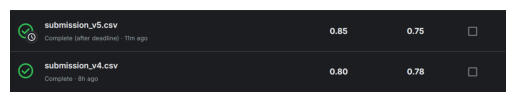

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open('/content/drive/MyDrive/RAG/Screenshot 2026-03-29 114921.png')
plt.imshow(img)
plt.axis('off')

---
## Cell 0: Config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os, re

DRIVE_BASE = '/content/drive/MyDrive/RAG'
DATA_DIR   = f'{DRIVE_BASE}/data'
KB_DIR     = f'{DATA_DIR}/knowledge_base'
CACHE_DIR  = f'{DRIVE_BASE}/cache_v3'   # ใช้ cache เดิม (BGE-M3 เหมือนกัน)
OUTPUT_DIR = f'{DRIVE_BASE}/output'

THAILLM_API_KEY = 'YOUR_THAILLM_API_KEY'
LLM_MODEL       = 'openthaigpt'   # ใช้เหมือนเดิม

# === Adaptive TOP_K ===
TOP_K_RETRIEVE  = 20   # ดึงมาเยอะก่อน (pool ใหญ่)
TOP_K_SIMPLE    = 5    # single-product, simple fact
TOP_K_COMPARE   = 8    # เปรียบเทียบ 2 สินค้า
TOP_K_MULTI     = 10   # 3+ สินค้า หรือ policy+calc

RRF_K       = 60
MAX_TOKENS  = 4048   # openthaigpt ต้องการ tokens สำหรับ think
N_QUESTIONS = 100

os.makedirs(CACHE_DIR,  exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print('Config v5 ready')
print(f'   LLM: {LLM_MODEL} | TOP_K: simple={TOP_K_SIMPLE}, compare={TOP_K_COMPARE}, multi={TOP_K_MULTI}')
print(f'   Cache: {CACHE_DIR}')

Mounted at /content/drive
Config v5 ready
   LLM: openthaigpt | TOP_K: simple=5, compare=8, multi=10
   Cache: /content/drive/MyDrive/RAG/cache_v3


---
## Cell 1: Install

In [ ]:
!pip install -q sentence-transformers rank-bm25 requests numpy pythainlp
import pythainlp
from pythainlp.corpus import download as nlp_download
try:
    nlp_download('tnc', force=False)
except:
    pass
print('Done!')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.8/19.8 MB 79.6 MB/s eta 0:00:00
Corpus not found: tnc
Done!


---
## Cell 2: LLM + Parse


In [ ]:
import re, time, requests

def ask_llm(messages, model=None, max_tokens=MAX_TOKENS, max_retries=5):
    if model is None:
        model = LLM_MODEL
    url     = f'http://thaillm.or.th/api/{model}/v1/chat/completions'
    headers = {'Content-Type': 'application/json', 'apikey': THAILLM_API_KEY}
    payload = {'model': '/model', 'messages': messages,
                'max_tokens': max_tokens, 'temperature': 0}
    for attempt in range(max_retries):
        try:
            resp = requests.post(url, headers=headers, json=payload, timeout=90)
            if resp.status_code == 429:
                wait = min(2 ** attempt, 30)
                print(f'    Rate limit, wait {wait}s...')
                time.sleep(wait)
                continue
            resp.raise_for_status()
            return resp.json()['choices'][0]['message']['content'].strip()
        except requests.exceptions.Timeout:
            wait = 2 ** attempt
            print(f'    Timeout attempt {attempt+1}, retry {wait}s...')
            time.sleep(wait)
        except requests.exceptions.RequestException as e:
            wait = 2 ** attempt
            print(f'    Error: {e} attempt {attempt+1}, retry {wait}s...')
            time.sleep(wait)
    return None


def parse_answer(text):
    """Robust parser — handles think blocks + Thai patterns"""
    if text is None:
        return None
    clean = re.sub(r'<think>.*?</think>', '', text, flags=re.DOTALL)
    clean = re.sub(r'<think>.*$', '', clean, flags=re.DOTALL).strip()
    if not clean:
        return None
    patterns = [
        r'ANSWER\s*:\s*(\d{1,2})',
        r'(?:ข้อ|ตอบข้อ|คำตอบ(?:คือ)?(?:ข้อ)?)\s*(\d{1,2})',
        r'\b(\d{1,2})\b',
    ]
    for pat in patterns:
        m = re.search(pat, clean, re.IGNORECASE)
        if m:
            val = int(m.group(1))
            if 1 <= val <= 10:
                return val
    return None


print('Testing LLM...')
test_resp = ask_llm(
    [{'role': 'user', 'content': 'ตอบในรูปแบบ ANSWER: X เท่านั้น 2+3=?'}],
    max_tokens=30
)
print(f'   Raw: {repr(test_resp)}')
print(f'   Parsed: {parse_answer(test_resp)}')
print('LLM OK!' if test_resp else 'LLM ERROR')

Testing LLM...
   Raw: '<think>\nคำถามนี้ต้องการคำตอบที่เป็นตัวเลขเพียงอย่างเดียว ดังนั้นต'
   Parsed: None
LLM OK!


---
## Cell 3: Intent Classifier + Query Decomposer (V5 NEW)

### หัวใจหลักของ V5

แทนที่จะ regex-based `extract_core_query`

ใช้ 2 ระดับ:
1. **Rule-based Intent Classifier** (เร็ว, ฟรี) — แยก 5 ประเภทคำถาม
2. **LLM Query Decomposer** (เฉพาะ LONG/COMPLEX) — ให้ LLM สรุป intent + entities สำคัญ

#### 5 Intent Types:
- `SIMPLE_FACT`: ถามข้อมูลเดียวจากสินค้าเดียว (TOP_K=5)
- `COMPARE`: เปรียบเทียบ 2 สินค้า/รุ่น (TOP_K=8)
- `MULTI_PRODUCT`: 3+ สินค้า หรือ recommendation (TOP_K=10)
- `POLICY_CALC`: นโยบาย+คำนวณ ค่าส่ง/คะแนน/ประกัน (TOP_K=10)
- `LONG_CONTEXT`: คำถามยาวที่ฝัง product question ไว้ (TOP_K=8)

In [ ]:
from pythainlp.tokenize import word_tokenize

# === Named Entities ===
BRAND_NAMES = [
    'arcwave', 'อาร์คเวฟ', 'daonuea', 'ดาวเหนือ', 'judchuem', 'จัดเจิม',
    'saifah', 'สายฟ้า', 'wongkhojon', 'วงโคจร', 'kluensiang', 'คลื่นเสียง',
    'pulsegear', 'novabuds', 'novatech', 'zenbyte',
]
PRODUCT_NAMES = [
    'airbook', 'stormbook', 'creatorbook', 'flexbook', 'probook', 'studybook', 'slimbook',
    'watch s3', 'watch s3 pro', 'watch s3 ultra', 'watch s3 se', 'watch sport',
    'headpro', 'headpro x1', 'headon', 'headon 500', 'headon 300',
    'buds z5', 'buds z5 pro', 'novabuds pro', 'studiobuds', 'studiobuds pro',
    'soundbar', 'soundpillar', 'soundbar 300', 'soundbar pro', 'soundpillar 300',
    'tower x10', 'mini pc', 'all-in-one', 'all in one',
    'rugged r1', 'duopad', 'tab a5', 'tab s8', 'tab s9', 'tab kid', 'tab draw',
    'band 8', 'band 8 pro', 'sport g1', 'sport x', 'sport lite',
    'qipad', 'chargepad', 'hub 7', 'hub 4', 'dock pro', 'dock airbook',
    'saifah pen', 'pen gen 2',
    'x9 pro', 'x9 fe', 'x9', 'v7',
    'power bank 30', '30000', '30,000',
    'g5', 'g7', 'proview 27',
    'studioprox1', 'studiopro m1',
]
POLICY_KEYWORDS = [
    'คืนสินค้า', 'คืนเงิน', 'ยกเลิก', 'ยกเลิกคำสั่ง', 'ประกัน', 'รับประกัน', 'วอแรนตี้',
    'จัดส่ง', 'ค่าส่ง', 'เดลิเวอรี', 'ขนส่ง', 'วันทำการ', 'tracking',
    'สมาชิก', 'แต้ม', 'point', 'points', 'คะแนน', 'ระดับ', 'gold', 'platinum', 'silver',
    'warranty', 'return', 'refund', 'shipping', 'cancel', 'membership',
    'ชั้น', 'ลิฟต์', 'mah', 'เกาะ', 'ต่างจังหวัด', 'ปริมณฑล',
    'care+', 'careplus', 'on-site', 'onsite', 'pre-order', 'preorder', 'พรีออเดอร์',
    'หักค่า', 'ค่าธรรมเนียม', 'ดอกเบี้ย', 'ผ่อน',
]
COMPARE_KEYWORDS = [
    'ต่างกัน', 'เปรียบเทียบ', 'กับ', 'vs', 'versus', 'เหมือนกัน', 'ต่างอย่างไร',
    'อันไหน', 'ตัวไหน', 'รุ่นไหน', 'ดีกว่า', 'เลือก', 'ควรซื้อ',
]
MULTI_KEYWORDS = [
    'ดีที่สุด', 'แนะนำ', 'เหมาะกับ', 'มีรุ่นไหนบ้าง', 'กี่รุ่น', 'ทุกรุ่น',
    'งบ', 'ราคาไม่เกิน', 'งบไม่เกิน', 'ดูได้กี่', 'ซื้อได้กี่',
]
CALC_KEYWORDS = [
    'รวม', 'ทั้งหมด', 'ได้กี่', 'เท่าไหร่', 'กี่บาท', 'กี่ points', 'กี่คะแนน',
    'คำนวณ', 'จ่าย', 'ราคา', 'ค่า',
]


def classify_intent(question):
    """
    แยกประเภทคำถามเป็น 5 ประเภท
    Returns: (intent_type, top_k, extra_info_dict)
    """
    q_lower = question.lower()
    q_len   = len(question)

    # นับ product mentions
    found_products = [p for p in PRODUCT_NAMES if p.lower() in q_lower]
    found_brands   = [b for b in BRAND_NAMES   if b.lower() in q_lower]
    found_codes    = re.findall(r'[A-Z]{2}-[A-Z]{2}-\d{3}', question)
    has_policy     = any(kw.lower() in q_lower for kw in POLICY_KEYWORDS)
    has_compare    = any(kw in question for kw in COMPARE_KEYWORDS)
    has_multi      = any(kw in question for kw in MULTI_KEYWORDS)
    has_calc       = any(kw in question for kw in CALC_KEYWORDS)

    # ประมาณจำนวน unique products ที่ถูกถาม
    # ถ้ามี 'กับ' หรือ 'และ' ระหว่างชื่อสินค้า => หลายสินค้า
    n_products_est = len(set(found_products)) + len(found_codes)

    # Long question (embedded product question)
    if q_len > 200:
        if found_products or found_codes:
            return 'LONG_CONTEXT', TOP_K_COMPARE, {
                'products': found_products, 'brands': found_brands, 'codes': found_codes
            }

    # Policy + Calculation
    if has_policy and has_calc:
        return 'POLICY_CALC', TOP_K_MULTI, {
            'products': found_products, 'brands': found_brands, 'codes': found_codes,
            'needs_policy': True
        }

    # Multi-product recommendation
    if has_multi or n_products_est >= 3:
        return 'MULTI_PRODUCT', TOP_K_MULTI, {
            'products': found_products, 'brands': found_brands, 'codes': found_codes
        }

    # Compare 2 products
    if has_compare and n_products_est >= 2:
        return 'COMPARE', TOP_K_COMPARE, {
            'products': found_products, 'brands': found_brands, 'codes': found_codes
        }

    # Policy-only
    if has_policy:
        return 'POLICY_CALC', TOP_K_COMPARE, {
            'products': found_products, 'brands': found_brands, 'codes': found_codes,
            'needs_policy': True
        }

    # Simple single-product fact
    return 'SIMPLE_FACT', TOP_K_SIMPLE, {
        'products': found_products, 'brands': found_brands, 'codes': found_codes
    }


def llm_decompose_query(question):
    """
    ใช้ LLM สรุป intent + entities จากคำถามยาว/ซับซ้อน
    เรียกเฉพาะ LONG_CONTEXT หรือ MULTI_PRODUCT ที่ซับซ้อน

    Returns: str (core search query) หรือ original question ถ้า API fail
    """
    prompt = f"""จากคำถามลูกค้าร้านฟ้าใหม่ต่อไปนี้ สรุปให้สั้นที่สุดว่า:
- ถามเรื่องสินค้าอะไร (ชื่อรุ่น/ยี่ห้อ)
- ถามข้อมูลอะไร (spec/ราคา/นโยบาย/เปรียบเทียบ)
ตอบสั้นๆ 1-2 บรรทัด ภาษาไทย ไม่ต้องอธิบาย:

คำถาม: {question[:500]}"""

    resp = ask_llm([{'role': 'user', 'content': prompt}], max_tokens=80)
    if resp:
        # ตัด think blocks
        clean = re.sub(r'<think>.*?</think>', '', resp, flags=re.DOTALL).strip()
        clean = re.sub(r'<think>.*$', '', clean, flags=re.DOTALL).strip()
        if len(clean) > 10:
            return clean
    return question  # fallback


def build_search_query(question, intent_type, entities, choices):
    """
    V5: สร้าง search query ที่ดีขึ้นตาม intent

    V4 ปัญหา:
    - dense ใช้ core_q (ดึงจาก regex)
    - bm25 ใช้ aug_q (question + choice specs)

    V5:
    - dense: question + choice PRODUCT NAMES (ทำให้ semantic รู้ว่าถามเรื่องอะไร)
    - bm25: question + choice spec numbers + product codes
    """
    q_lower = question.lower()

    # สร้าง choice summary สำหรับ dense
    choice_texts = [v for k, v in choices.items() if k not in ('9', '10')]

    # extract product names from choices (เพิ่ม semantic context)
    choice_products = []
    for ct in choice_texts:
        for pname in PRODUCT_NAMES:
            if pname.lower() in ct.lower():
                choice_products.append(pname)

    # Dense query: question + unique product context
    extra_ctx = ' '.join(list(dict.fromkeys(
        entities.get('products', []) + entities.get('brands', []) + choice_products
    ))[:5])
    dense_q = f"{question} {extra_ctx}".strip()[:400]

    # BM25 query: question + codes + numbers from choices
    all_choice_text = ' '.join(choice_texts)
    codes_in_choices = re.findall(r'[A-Z]{2}-[A-Z]{2}-\d{3}', all_choice_text)
    specs_in_choices = re.findall(
        r'\d+(?:\.\d+)?\s*(?:GB|TB|MHz|Hz|W|mAh|ATM|kg|นิ้ว|ชม|บาท|฿|%|dB|mm|m|Wh)',
        all_choice_text
    )
    bm25_extras = (entities.get('codes', []) + codes_in_choices + specs_in_choices[:4])
    bm25_q = (question + ' ' + ' '.join(set(bm25_extras)))[:400]

    return dense_q, bm25_q


# ===== Tests =====
print('=== Testing Intent Classifier ===')
test_qs = [
    'Watch S3 Ultra กันน้ำได้กี่ ATM ครับ',
    'HeadPro X1 กับ HeadOn 500 สเปคต่างกันยังไง',
    'สมาชิก Gold ซื้อ StormBook G5 จะได้กี่ Points',
    'สั่ง SoundBar Pro 500 ส่งชั้น 6 ไม่มีลิฟต์ ค่าส่งเท่าไหร่',
    'มีงบ 5000 อยากได้หูฟังครอบหูมีรุ่นไหนบ้าง',
    'เฮ้ยย อ่านเยอะมากเลย ... สายฟ้า Rugged R1 กันน้ำระดับไหนคะ ดำน้ำได้มั้ย ประกันคุ้มครองมั้ย',
    'StormBook G5, G5 รุ่น 2024, กับ G7 ตัวไหนใช้ DDR5',
]
for q in test_qs:
    intent, top_k, ents = classify_intent(q)
    print(f'  [{intent:14} | K={top_k}] {q[:55]}')
    if ents.get('products'):
        print(f'        products: {ents["products"][:3]}')

print('\nIntent Classifier V5 ready!')

=== Testing Intent Classifier ===
  [SIMPLE_FACT    | K=5] Watch S3 Ultra กันน้ำได้กี่ ATM ครับ
        products: ['watch s3', 'watch s3 ultra']
  [MULTI_PRODUCT  | K=10] HeadPro X1 กับ HeadOn 500 สเปคต่างกันยังไง
        products: ['headpro', 'headpro x1', 'headon']
  [POLICY_CALC    | K=10] สมาชิก Gold ซื้อ StormBook G5 จะได้กี่ Points
        products: ['stormbook', 'g5']
  [POLICY_CALC    | K=10] สั่ง SoundBar Pro 500 ส่งชั้น 6 ไม่มีลิฟต์ ค่าส่งเท่าไห
        products: ['soundbar', 'soundbar pro']
  [MULTI_PRODUCT  | K=10] มีงบ 5000 อยากได้หูฟังครอบหูมีรุ่นไหนบ้าง
  [POLICY_CALC    | K=8] เฮ้ยย อ่านเยอะมากเลย ... สายฟ้า Rugged R1 กันน้ำระดับไห
        products: ['rugged r1']
  [MULTI_PRODUCT  | K=10] StormBook G5, G5 รุ่น 2024, กับ G7 ตัวไหนใช้ DDR5
        products: ['stormbook', 'g5', 'g7']

Intent Classifier V5 ready!


---
## Cell 4: Load Knowledge Base (เหมือน v4)

In [ ]:
from pathlib import Path
from collections import defaultdict

BRAND_MAP = {
    'AW': 'ArcWave (อาร์คเวฟ)', 'DN': 'DaoNuea (ดาวเหนือ)',
    'JC': 'JudChuem (จัดเจิม)', 'SF': 'SaiFah (สายฟ้า)',
    'WJ': 'WongKhoJon (วงโคจร)', 'KS': 'KluenSiang (คลื่นเสียง)',
    'PG': 'PulseGear', 'NB': 'NovaBuds', 'NT': 'NovaTech', 'ZB': 'ZenByte',
}
CATEGORY_MAP = {
    'MN': 'Monitor', 'SK': 'Speaker/SoundBar', 'DT': 'Desktop',
    'LT': 'Laptop', 'CH': 'Charger', 'BK': 'BT Keyboard',
    'PH': 'Smartphone', 'WT': 'Smartwatch', 'HP': 'Headphone',
    'SP': 'Speaker', 'TB': 'Tablet', 'PW': 'Power Bank',
    'DC': 'Dock/Hub', 'FT': 'Fitness Band', 'EB': 'TWS Earbuds', 'HB': 'Hub',
}

def extract_metadata(filepath_str):
    filename  = Path(filepath_str).stem
    code_part = filename.split('_')[0]
    parts     = code_part.split('-')
    return {
        'brand'       : BRAND_MAP.get(parts[0], parts[0]) if parts else 'unknown',
        'category'    : CATEGORY_MAP.get(parts[1], parts[1]) if len(parts) > 1 else 'unknown',
        'product_code': '-'.join(parts[:3]) if len(parts) >= 3 else filename,
        'filename'    : filename,
    }

def split_by_sections(text, prefix, source, meta, folder, min_section_len=80):
    sections = re.split(r'\n(?=#{1,3} )', text)
    chunks, buffer = [], ''
    for sec in sections:
        sec = sec.strip()
        if not sec:
            continue
        if len(sec) < min_section_len:
            buffer = (buffer + '\n\n' + sec).strip() if buffer else sec
            continue
        if buffer:
            chunks.append({'text': prefix + buffer + '\n\n' + sec,
                           'source': source, 'folder': folder, 'metadata': meta})
            buffer = ''
        else:
            chunks.append({'text': prefix + sec,
                           'source': source, 'folder': folder, 'metadata': meta})
    if buffer:
        chunks.append({'text': prefix + buffer, 'source': source, 'folder': folder, 'metadata': meta})
    return chunks

def load_knowledge_base(kb_dir):
    kb_path = Path(kb_dir)
    chunks, stats = [], defaultdict(int)
    if not kb_path.exists():
        print(f'Directory not found: {kb_dir}')
        return [], {}
    for md_file in sorted(kb_path.rglob('*.md')):
        try:
            text = md_file.read_text(encoding='utf-8').strip()
            if not text:
                continue
            rel_path  = md_file.relative_to(kb_path)
            subfolder = rel_path.parts[0]
            meta      = extract_metadata(str(md_file))
            if subfolder == 'products':
                prefix = f"[สินค้า: {meta['product_code']} | แบรนด์: {meta['brand']} | ประเภท: {meta['category']}]\n"
            elif subfolder == 'policies':
                prefix = f'[นโยบายร้านฟ้าใหม่: {md_file.stem.replace("_"," ").replace("-"," ")}]\n'
            else:
                prefix = f'[ข้อมูลร้านฟ้าใหม่: {md_file.stem.replace("_"," ").replace("-"," ")}]\n'
            new_chunks = split_by_sections(text, prefix,
                                           str(rel_path), meta, subfolder)
            chunks.extend(new_chunks)
            stats[subfolder] += 1
        except Exception as e:
            print(f'Error reading {md_file}: {e}')
    return chunks, dict(stats)

# Build full-document index for force-retrieve (1 doc = 1 chunk)
def load_full_documents(kb_dir):
    """Load each MD file as a SINGLE chunk (for force-retrieve)"""
    kb_path = Path(kb_dir)
    doc_map = {}  # filename_stem -> {text, source, folder, metadata}
    for md_file in sorted(kb_path.rglob('*.md')):
        try:
            text = md_file.read_text(encoding='utf-8').strip()
            if not text:
                continue
            rel_path  = md_file.relative_to(kb_path)
            subfolder = rel_path.parts[0]
            meta      = extract_metadata(str(md_file))
            stem      = md_file.stem.lower()
            if subfolder == 'products':
                prefix = f"[สินค้า: {meta['product_code']} | แบรนด์: {meta['brand']} | ประเภท: {meta['category']}]\n"
            elif subfolder == 'policies':
                prefix = f'[นโยบายร้านฟ้าใหม่: {md_file.stem.replace("_"," ").replace("-"," ")}]\n'
            else:
                prefix = f'[ข้อมูลร้านฟ้าใหม่: {md_file.stem.replace("_"," ").replace("-"," ")}]\n'
            doc_map[stem] = {
                'text': prefix + text[:4000],  # max 4000 chars per full doc
                'source': str(rel_path),
                'folder': subfolder,
                'metadata': meta,
                'full_text': text,
            }
        except:
            pass
    return doc_map


print('Loading Knowledge Base...')
chunks, stats = load_knowledge_base(KB_DIR)
doc_map = load_full_documents(KB_DIR)   # V5: full document map

print(f'Loaded {len(chunks)} chunks | {len(doc_map)} documents')
for folder, cnt in sorted(stats.items()):
    print(f'   {folder}: {cnt} files')
print('KB ready!')

Loading Knowledge Base...
Loaded 857 chunks | 118 documents
   policies: 5 files
   products: 110 files
   store_info: 3 files
KB ready!


---
## Cell 5: Build/Load Index

In [ ]:
import numpy as np, pickle
from sentence_transformers import SentenceTransformer
from rank_bm25 import BM25Okapi
from pythainlp.tokenize import word_tokenize

MODEL_NAME   = 'BAAI/bge-m3'
EMBED_CACHE  = f'{CACHE_DIR}/bge_m3_v3.npy'
CHUNKS_CACHE = f'{CACHE_DIR}/chunks_v3.pkl'
BM25_CACHE   = f'{CACHE_DIR}/bm25_v3.pkl'

cache_ok = all(os.path.exists(p) for p in [EMBED_CACHE, CHUNKS_CACHE, BM25_CACHE])

if cache_ok:
    print('Found cache v3! Loading...')
    chunk_embeddings = np.load(EMBED_CACHE)
    with open(CHUNKS_CACHE, 'rb') as f:
        chunks = pickle.load(f)
    with open(BM25_CACHE, 'rb') as f:
        bm25 = pickle.load(f)
    print(f'   Embeddings: {chunk_embeddings.shape} | Chunks: {len(chunks)}')
    # โหลด embed_model สำหรับ encode query
    print('Loading embed model for query encoding...')
    embed_model = SentenceTransformer(MODEL_NAME)
    print('   embed_model ready')
else:
    print(f'Building index with {MODEL_NAME}...')
    embed_model = SentenceTransformer(MODEL_NAME)
    texts = [c['text'] for c in chunks]
    print(f'Embedding {len(texts)} chunks...')
    chunk_embeddings = embed_model.encode(
        texts, normalize_embeddings=True, show_progress_bar=True, batch_size=32)
    print(f'   Shape: {chunk_embeddings.shape}')
    tokenized = [word_tokenize(t, engine='newmm') for t in texts]
    bm25 = BM25Okapi(tokenized)
    np.save(EMBED_CACHE, chunk_embeddings)
    with open(CHUNKS_CACHE, 'wb') as f: pickle.dump(chunks, f)
    with open(BM25_CACHE,   'wb') as f: pickle.dump(bm25, f)
    print(f'Saved to {CACHE_DIR}')

print(f'\nIndex ready: {chunk_embeddings.shape[1]} dim, {len(chunks)} chunks')

Building index with BAAI/bge-m3...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

Embedding 857 chunks...


Batches:   0%|          | 0/27 [00:00<?, ?it/s]

   Shape: (857, 1024)
Saved to /content/drive/MyDrive/RAG/cache_v3

Index ready: 1024 dim, 857 chunks


---
## Cell 6: Smart Retrieval

1. **`doc_map` lookup**: O(1) แทน O(n) สำหรับ force-retrieve
2. **Guaranteed multi-doc**: ถ้า intent=COMPARE/MULTI ต้องได้ทุก product doc
3. **Policy force-add**: เพิ่ม policy chunk ก่อนเสมอถ้า POLICY_CALC
4. **LLM Decompose**: เฉพาะ LONG_CONTEXT ให้ LLM สรุป intent ก่อน dense search

In [ ]:
# === Build reverse index: product name -> chunk indices (ทำครั้งเดียว) ===
print('Building product->chunk reverse index...')
product_chunk_idx = defaultdict(list)  # product_name_lower -> [chunk_idx, ...]
for i, chunk in enumerate(chunks):
    text_lower = chunk['text'].lower()
    for pname in PRODUCT_NAMES:
        if pname.lower() in text_lower:
            product_chunk_idx[pname.lower()].append(i)
    for code in re.findall(r'[a-z]{2}-[a-z]{2}-\d{3}', text_lower):
        product_chunk_idx[code].append(i)

# Policy chunk indices
policy_chunk_idx = [i for i, c in enumerate(chunks) if c['folder'] == 'policies']
store_chunk_idx  = [i for i, c in enumerate(chunks) if c['folder'] == 'store_info']

print(f'   Product index entries: {len(product_chunk_idx)}')
print(f'   Policy chunks: {len(policy_chunk_idx)}')
print(f'   Store info chunks: {len(store_chunk_idx)}')


def dense_retrieve(query, k=TOP_K_RETRIEVE):
    q_emb   = embed_model.encode(query, normalize_embeddings=True)
    scores  = chunk_embeddings @ q_emb
    top_idx = np.argsort(scores)[::-1][:k]
    return list(top_idx), scores[top_idx]


def bm25_retrieve(query, k=TOP_K_RETRIEVE):
    tokens  = word_tokenize(query, engine='newmm')
    scores  = bm25.get_scores(tokens)
    top_idx = np.argsort(scores)[::-1][:k]
    return list(top_idx), scores[top_idx]


def force_retrieve_v5(entities, intent_type):
    """
    V5: Force-retrieve chunks ที่ match ทุก product/entity
    ใช้ reverse index แทน brute-force scan

    Returns: list of chunk indices (deduped)
    """
    forced = []
    seen   = set()

    products = entities.get('products', [])
    codes    = entities.get('codes', [])

    # Force by product code (highest priority)
    for code in codes:
        for idx in product_chunk_idx.get(code.lower(), []):
            if idx not in seen:
                forced.append(idx)
                seen.add(idx)

    # Force by product name — limit 2 chunks per product to avoid bias
    for prod in products:
        prod_lower = prod.lower()
        candidates = product_chunk_idx.get(prod_lower, [])
        # เรียงตามความยาว (chunk ยาว = มีข้อมูลมากกว่า)
        cands_sorted = sorted(candidates, key=lambda i: len(chunks[i]['text']), reverse=True)
        added = 0
        for idx in cands_sorted:
            if idx not in seen and added < 2:
                forced.append(idx)
                seen.add(idx)
                added += 1

    # Policy: ถ้า POLICY_CALC ให้ add policy chunk top-scored
    if intent_type == 'POLICY_CALC' and entities.get('needs_policy', False):
        for idx in policy_chunk_idx[:3]:
            if idx not in seen:
                forced.append(idx)
                seen.add(idx)

    return forced


def smart_retrieve_v5(question, choices):
    """
    V5 Main Retrieval:
    1. Intent classification
    2. Build smart search queries (dense + bm25)
    3. [Optional] LLM decompose for LONG_CONTEXT
    4. Dense + BM25 with intent-weighted RRF
    5. Force-retrieve guaranteed relevant chunks
    6. Merge with adaptive TOP_K
    """
    q_lower = question.lower()

    # Step 1: Intent
    intent_type, top_k, entities = classify_intent(question)

    # Step 2: Search queries
    dense_q, bm25_q = build_search_query(question, intent_type, entities, choices)

    # Step 3: LLM decompose (LONG_CONTEXT only)
    if intent_type == 'LONG_CONTEXT':
        llm_core = llm_decompose_query(question)
        # ใช้ LLM core สำหรับ dense
        dense_q = llm_core + ' ' + ' '.join(entities.get('products', []))[:200]

    # Step 4: RRF weights ตาม intent
    has_codes = bool(entities.get('codes'))
    if intent_type == 'POLICY_CALC':
        bm25_w, dense_w = 2.0, 1.0   # BM25 ดีกว่าสำหรับ spec/number
    elif has_codes:
        bm25_w, dense_w = 2.5, 1.0
    elif intent_type in ('COMPARE', 'MULTI_PRODUCT'):
        bm25_w, dense_w = 1.0, 1.8   # Dense ดีกว่าสำหรับ semantic comparison
    elif intent_type == 'LONG_CONTEXT':
        bm25_w, dense_w = 1.0, 2.0   # Dense ดีกว่าสำหรับ LLM-summarized query
    else:
        bm25_w, dense_w = 1.2, 1.5

    d_idx, _ = dense_retrieve(dense_q, k=TOP_K_RETRIEVE)
    b_idx, _ = bm25_retrieve(bm25_q,  k=TOP_K_RETRIEVE)

    # RRF fusion
    rrf_scores = {}
    for rank, idx in enumerate(d_idx, 1):
        rrf_scores[idx] = rrf_scores.get(idx, 0.0) + dense_w / (RRF_K + rank)
    for rank, idx in enumerate(b_idx, 1):
        rrf_scores[idx] = rrf_scores.get(idx, 0.0) + bm25_w  / (RRF_K + rank)

    # Policy re-rank: ถ้า POLICY_CALC ให้ policy chunks มา top
    if intent_type == 'POLICY_CALC':
        policy_bonus = 0.1
        for idx in rrf_scores:
            if chunks[idx]['folder'] == 'policies':
                rrf_scores[idx] += policy_bonus

    sorted_idx = sorted(rrf_scores, key=lambda x: rrf_scores[x], reverse=True)

    # Step 5: Force-retrieve
    forced_idx = force_retrieve_v5(entities, intent_type)

    # Step 6: Merge (forced first, then RRF)
    seen      = set(forced_idx)
    remainder = [i for i in sorted_idx if i not in seen]
    final_pool = forced_idx + remainder

    return [chunks[i] for i in final_pool[:top_k]], intent_type, entities


# === Test ===
print('\nTesting Smart Retrieval V5:')
test_qs = [
    ('Watch S3 Ultra กันน้ำได้กี่ ATM ครับ', {}),
    ('HeadPro X1 กับ HeadOn 500 สเปคต่างกันยังไง', {}),
    ('สมาชิก Gold ซื้อ StormBook G5 ราคา 32990 จะได้กี่ Points', {}),
    ('สั่ง SoundBar Pro 500 ไปชั้น 6 ไม่มีลิฟต์ กรุงเทพ ค่าส่งเท่าไหร่', {}),
    ('StormBook G5, G5 รุ่น 2024, กับ G7 ตัวไหนใช้ DDR5', {}),
]
for tq, tc in test_qs:
    r, intent, ents = smart_retrieve_v5(tq, {str(i): '' for i in range(1,11)})
    print(f'\n  [{intent}] Q: {tq[:50]}')
    print(f'  Entities: {ents.get("products",[][:2])}')
    for i, c in enumerate(r[:4], 1):
        print(f'    [{i}] [{c["folder"]}] {c["source"].split("/")[-1][:45]}')

print('\nRetrieval V5 ready!')

Building product->chunk reverse index...
   Product index entries: 166
   Policy chunks: 94
   Store info chunks: 48

Testing Smart Retrieval V5:

  [SIMPLE_FACT] Q: Watch S3 Ultra กันน้ำได้กี่ ATM ครับ
  Entities: ['watch s3', 'watch s3 ultra']
    [1] [products] WK-SW-001_wongkhojon_watch_s3_ultra.md
    [2] [products] WK-SW-001_wongkhojon_watch_s3_ultra.md
    [3] [products] WK-SW-002_wongkhojon_watch_s3_pro.md
    [4] [products] WK-SW-008_wongkhojon_watch_s2_pro.md

  [MULTI_PRODUCT] Q: HeadPro X1 กับ HeadOn 500 สเปคต่างกันยังไง
  Entities: ['headpro', 'headpro x1', 'headon', 'headon 500']
    [1] [policies] warranty_policy.md
    [2] [products] KS-HP-002_kluensiang_headpro_x1_se.md
    [3] [products] KS-HP-001_kluensiang_headpro_x1.md
    [4] [products] KS-HP-001_kluensiang_headpro_x1.md

  [POLICY_CALC] Q: สมาชิก Gold ซื้อ StormBook G5 ราคา 32990 จะได้กี่ 
  Entities: ['stormbook', 'g5']
    [1] [products] DN-LT-010_daonuea_stormbook_g9_titan.md
    [2] [products] DN-LT-007_daonu

---
## Cell 7: Prompt Builder

แยก **3 prompt modes** ตาม intent:
1. **SIMPLE_FACT**: ตอบตรง ๆ จาก spec ในเอกสาร
2. **COMPARE/MULTI_PRODUCT**: บอก model ให้เปรียบเทียบจากทุก doc ที่ให้
3. **POLICY_CALC**: บอก model ให้คำนวณทีละขั้น แล้วค่อยเลือกข้อ

และเพิ่ม **ตัวเลขคำแนะนำ** สำหรับ choice 9 vs 10 ให้ชัดเจนขึ้น

In [ ]:
SYSTEM_BASE = """คุณเป็น AI ผู้ช่วยของร้านฟ้าใหม่ (FahMai) ร้านอิเล็กทรอนิกส์ออนไลน์ภาษาไทย

กฎสำคัญ:
- ข้อ 9 = "ไม่มีข้อมูลนี้ในฐานข้อมูล" → ใช้ถ้าคำถามเกี่ยวกับฟ้าใหม่/สินค้า แต่ไม่พบในเอกสาร
- ข้อ 10 = "ไม่เกี่ยวกับร้านฟ้าใหม่" → ใช้ถ้าคำถามเป็นเรื่องอื่นทั้งหมด (อาหาร ท่องเที่ยว การเงิน ฯลฯ)
- ตอบเฉพาะ: ANSWER: [1-10]"""

SYSTEM_SIMPLE = SYSTEM_BASE + """

วิธีตอบ: อ่านเอกสาร → หา spec/ข้อมูลที่ตรงกับคำถาม → เลือกข้อที่ถูกต้อง → ตอบ ANSWER: X"""

SYSTEM_COMPARE = SYSTEM_BASE + """

วิธีตอบ:
1. อ่านเอกสารทุกชิ้นอย่างละเอียด
2. เปรียบเทียบ spec ของสินค้าแต่ละตัวที่ถูกถาม
3. เทียบกับตัวเลือกทีละข้อ
4. ตอบ ANSWER: X"""

SYSTEM_CALC = SYSTEM_BASE + """

วิธีตอบ:
1. อ่านนโยบาย/เงื่อนไขจากเอกสาร
2. ระบุตัวเลข/ค่าที่เกี่ยวข้อง
3. คำนวณทีละขั้นตอน
4. จับคู่กับตัวเลือก
5. ตอบ ANSWER: X"""

FOLDER_LABEL = {'products': 'สินค้า', 'policies': 'นโยบาย', 'store_info': 'ข้อมูลร้าน'}


def get_system_prompt(intent_type):
    if intent_type == 'POLICY_CALC':
        return SYSTEM_CALC
    elif intent_type in ('COMPARE', 'MULTI_PRODUCT'):
        return SYSTEM_COMPARE
    else:
        return SYSTEM_SIMPLE


def build_messages_v5(question, choices, retrieved_chunks, intent_type='SIMPLE_FACT'):
    """
    V5: Intent-aware prompt builder
    - แยก system prompt ตาม intent
    - จัด context โดย policy chunks ขึ้นก่อนถ้าเป็น POLICY_CALC
    - truncate ต่างกัน: simple=2000, compare/multi=2500, calc=3000 per chunk
    """
    # Truncate per chunk ตาม intent
    if intent_type == 'POLICY_CALC':
        max_per_chunk = 3500
    elif intent_type in ('COMPARE', 'MULTI_PRODUCT'):
        max_per_chunk = 2500
    else:
        max_per_chunk = 2000

    # Sort: policy ขึ้นก่อนถ้า POLICY_CALC
    if intent_type == 'POLICY_CALC':
        policy_chunks  = [c for c in retrieved_chunks if c['folder'] == 'policies']
        product_chunks = [c for c in retrieved_chunks if c['folder'] != 'policies']
        ordered_chunks = policy_chunks + product_chunks
    else:
        ordered_chunks = retrieved_chunks

    context_parts = []
    for i, chunk in enumerate(ordered_chunks, 1):
        label  = FOLDER_LABEL.get(chunk.get('folder', ''), '')
        source = chunk.get('source', 'unknown')
        text   = chunk['text'][:max_per_chunk]
        context_parts.append(f'[{label} {i} | {source}]\n{text}')

    sep     = '\n\n' + '─' * 40 + '\n\n'
    context = sep.join(context_parts)

    choices_text = '\n'.join(
        f'ข้อ {k}: {v}' for k, v in sorted(choices.items(), key=lambda x: int(x[0]))
    )

    # Intent hint ใน user message
    intent_hint = ''
    if intent_type == 'POLICY_CALC':
        intent_hint = '\n[หมายเหตุ: คำถามนี้อาจต้องคำนวณตามนโยบาย กรุณาคำนวณทีละขั้นก่อนตอบ]'
    elif intent_type in ('COMPARE', 'MULTI_PRODUCT'):
        intent_hint = '\n[หมายเหตุ: คำถามนี้เปรียบเทียบหลายสินค้า กรุณาตรวจสอบเอกสารทุกชิ้น]'
    elif intent_type == 'LONG_CONTEXT':
        intent_hint = '\n[หมายเหตุ: คำถามที่สำคัญอยู่ท้ายข้อความ กรุณาระบุว่าถามเรื่องอะไรก่อนตอบ]'

    user_content = (
        f'ข้อมูลจากฐานข้อมูลร้านฟ้าใหม่:\n\n'
        f'{context}\n\n'
        f'{"=" * 50}\n'
        f'คำถาม: {question}'
        f'{intent_hint}\n\n'
        f'ตัวเลือก:\n{choices_text}\n\n'
        f'ตอบ ANSWER: [1-10] ทันที'
    )

    return [
        {'role': 'system', 'content': get_system_prompt(intent_type)},
        {'role': 'user',   'content': user_content},
    ]


print('Prompt V5 ready!')
print(f'  SIMPLE:  {len(SYSTEM_SIMPLE)} chars')
print(f'  COMPARE: {len(SYSTEM_COMPARE)} chars')
print(f'  CALC:    {len(SYSTEM_CALC)} chars')

Prompt V5 ready!
  SIMPLE:  395 chars
  COMPARE: 440 chars
  CALC:    437 chars


---
## Cell 8: Load Questions

In [ ]:
import csv

def load_questions(filepath, n=N_QUESTIONS):
    questions = []
    with open(filepath, encoding='utf-8') as f:
        for row in csv.DictReader(f):
            choices = {str(i): row[f'choice_{i}'] for i in range(1, 11)}
            questions.append({'id': int(row['id']), 'question': row['question'], 'choices': choices})
    return questions[:n]

questions = load_questions(f'{DATA_DIR}/questions.csv')
print(f'Loaded {len(questions)} questions')

# Preview intent distribution
from collections import Counter
intent_dist = Counter()
for q in questions:
    intent, top_k, _ = classify_intent(q['question'])
    intent_dist[intent] += 1

print('\nIntent distribution:')
for intent, cnt in sorted(intent_dist.items(), key=lambda x: -x[1]):
    print(f'  {intent:16}: {cnt} ข้อ')

Loaded 100 questions

Intent distribution:
  SIMPLE_FACT     : 50 ข้อ
  MULTI_PRODUCT   : 24 ข้อ
  POLICY_CALC     : 16 ข้อ
  COMPARE         : 9 ข้อ
  LONG_CONTEXT    : 1 ข้อ


---
## Cell 9: Run Full Pipeline V5

- ใช้ `smart_retrieve_v5()` + `build_messages_v5()`
- Log intent type ด้วย
- Cache path ใหม่ `results_v5.json`

In [ ]:
import json

RESULTS_PATH = f'{CACHE_DIR}/results_v5.json'


def run_pipeline_v5(questions, save_every=10):
    results = {}
    if os.path.exists(RESULTS_PATH):
        with open(RESULTS_PATH, 'r', encoding='utf-8') as f:
            saved = json.load(f)
            results = {int(k): v for k, v in saved.items()}
        print(f'Resume: found {len(results)} done')

    total, failed = len(questions), []
    print(f'\nStarting {total} questions...')
    print(f'   Model: {LLM_MODEL} | MaxTokens: {MAX_TOKENS}')
    print(f'   TOP_K: simple={TOP_K_SIMPLE}, compare={TOP_K_COMPARE}, multi={TOP_K_MULTI}')
    print('=' * 70)

    start_time = time.time()

    for idx, q in enumerate(questions, 1):
        qid = q['id']
        if qid in results:
            r = results[qid]
            print(f'Q{qid:>3} [{idx:>3}/{total}] SKIP (ans={r["answer"]} | {r.get("intent","?")})')
            continue

        q_start = time.time()

        # V5 pipeline
        retrieved, intent_type, entities = smart_retrieve_v5(q['question'], q['choices'])
        sources  = [r['source'] for r in retrieved]
        messages = build_messages_v5(q['question'], q['choices'], retrieved, intent_type)
        raw      = ask_llm(messages)
        answer   = parse_answer(raw)

        # Retry once if parse fails
        if answer is None:
            print(f'    Parse fail Q{qid}: {repr(raw)[:60]}, retrying...')
            raw2   = ask_llm(messages)
            answer = parse_answer(raw2)
            if answer is None:
                answer = 9
                failed.append(qid)
                print(f'    Q{qid}: default -> 9')

        elapsed  = time.time() - q_start
        ent_list = (entities.get('products', []) + entities.get('codes', []))[:3]

        results[qid] = {
            'answer'  : answer,
            'raw'     : raw,
            'sources' : sources[:3],
            'time_s'  : round(elapsed, 1),
            'intent'  : intent_type,
            'entities': ent_list,
            'n_chunks': len(retrieved),
        }

        top_src = sources[0].split('/')[-1][:35] if sources else '?'
        ent_str = ','.join(ent_list[:2]) if ent_list else '-'
        print(f'Q{qid:>3} [{idx:>3}/{total}] ans={answer:>2} | {elapsed:.1f}s | [{intent_type[:6]}] {q["question"][:35]}')
        print(f'       src={top_src} | ent=[{ent_str}] | chunks={len(retrieved)}')

        if idx % save_every == 0 or idx == total:
            with open(RESULTS_PATH, 'w', encoding='utf-8') as f:
                json.dump({str(k): v for k, v in results.items()}, f, ensure_ascii=False, indent=2)
            print(f'   Checkpoint ({len(results)}/{total})')

        time.sleep(0.5)

    total_time = time.time() - start_time
    print('\n' + '=' * 70)
    print(f'Done! {len(results)}/{total} in {total_time:.0f}s ({total_time/60:.1f} min)')
    if failed:
        print(f'   Parse fail (->9): {len(failed)} QIDs: {failed}')

    from collections import Counter
    dist   = Counter(v['answer'] for v in results.values())
    intent_cnt = Counter(v.get('intent', '?') for v in results.values())
    print('\nAnswer Distribution:')
    for ans in range(1, 11):
        cnt  = dist.get(ans, 0)
        bar  = '█' * min(cnt, 30)
        note = ' <- no_info' if ans == 9 else ' <- irrelevant' if ans == 10 else ''
        print(f'   ans {ans:>2}: {cnt:>3} {bar}{note}')

    print('\nIntent breakdown:')
    for intent, cnt in sorted(intent_cnt.items(), key=lambda x: -x[1]):
        print(f'   {intent:16}: {cnt}')

    return results


results = run_pipeline_v5(questions)


Starting 100 questions...
   Model: openthaigpt | MaxTokens: 4048
   TOP_K: simple=5, compare=8, multi=10
Q  1 [  1/100] ans= 5 | 3.5s | [SIMPLE]
       chunks=5
Q  2 [  2/100] ans= 7 | 1.8s | [SIMPLE]
       chunks=5
Q  3 [  3/100] ans= 2 | 2.6s | [SIMPLE]
       chunks=5
Q  4 [  4/100] ans= 6 | 1.8s | [SIMPLE]
       chunks=5
Q  5 [  5/100] ans= 6 | 2.9s | [SIMPLE]
       chunks=5
Q  6 [  6/100] ans= 8 | 2.0s | [SIMPLE]
       chunks=5
Q  7 [  7/100] ans= 1 | 5.4s | [SIMPLE]
       chunks=5
Q  8 [  8/100] ans= 9 | 2.1s | [POLICY]
       chunks=8
Q  9 [  9/100] ans= 4 | 7.4s | [LONG_C]
       chunks=8
Q 10 [ 10/100] ans= 7 | 5.7s | [SIMPLE]
       chunks=5
   Checkpoint (10/100)
Q 11 [ 11/100] ans= 4 | 5.6s | [SIMPLE]
       chunks=5
Q 12 [ 12/100] ans= 1 | 4.4s | [SIMPLE]
       chunks=5
Q 13 [ 13/100] ans= 6 | 3.2s | [MULTI_]
       chunks=10
Q 14 [ 14/100] ans= 9 | 8.3s | [SIMPLE]
       chunks=5
Q 15 [ 15/100] ans= 7 | 3.8s | [SIMPLE]
       chunks=5
Q 16 [ 16/100] ans= 1 | 2.3s 

---
## Cell 10: Save Submission V5

In [ ]:
import csv

SUBMISSION_PATH = f'{OUTPUT_DIR}/submission_v5.csv'
with open(SUBMISSION_PATH, 'w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['id', 'answer'])
    for q in questions:
        qid    = q['id']
        answer = results.get(qid, {}).get('answer', 9)
        if not (1 <= answer <= 10):
            answer = 9
        writer.writerow([qid, answer])

rows = list(csv.DictReader(open(SUBMISSION_PATH, encoding='utf-8')))
print(f'Saved: {SUBMISSION_PATH}')
print(f'Rows  : {len(rows)} {"OK" if len(rows)==100 else "ERROR"}')
print(f'Values: {"OK" if all(1<=int(r["answer"])<=10 for r in rows) else "ERROR"}')
print(f'\nAll {len(results)} results:')
print(f'   {"id":>4}  {"ans":>3}  {"intent":>14}  core_q')
for qid in sorted(results.keys()):
    r = results[qid]
    print(f'   {qid:>4}  {r["answer"]:>3}  {r.get("intent","?"):>14}  {r.get("entities",[""])[0] if r.get("entities") else "-"}')
print(f'\nReady -> {SUBMISSION_PATH}')

Saved: /content/drive/MyDrive/RAG/output/submission_v5.csv
Rows  : 100 OK
Values: OK

All 100 results:
     id  ans          intent  core_q
      1    5     SIMPLE_FACT  watch s3
      2    7     SIMPLE_FACT  saifah pen
      3    2     SIMPLE_FACT  headpro
      4    6     SIMPLE_FACT  -
      5    6     SIMPLE_FACT  -
      6    8     SIMPLE_FACT  -
      7    1     SIMPLE_FACT  airbook
      8    9     POLICY_CALC  duopad
      9    4    LONG_CONTEXT  rugged r1
     10    7     SIMPLE_FACT  x9 pro
     11    4     SIMPLE_FACT  -
     12    1     SIMPLE_FACT  -
     13    6   MULTI_PRODUCT  -
     14    9     SIMPLE_FACT  x9 pro
     15    7     SIMPLE_FACT  -
     16    1   MULTI_PRODUCT  watch s3
     17    8     SIMPLE_FACT  -
     18    5     SIMPLE_FACT  -
     19    2     SIMPLE_FACT  -
     20    2   MULTI_PRODUCT  -
     21    3     SIMPLE_FACT  -
     22    6     POLICY_CALC  x9 pro
     23    3         COMPARE  watch s3
     24    3     SIMPLE_FACT  slimbook
     25    5   

---
## Cell 11: Debug Tool V5

แสดง intent + จำนวน chunks

In [ ]:
def debug_v5(qid, rerun=False):
    q = next((x for x in questions if x['id'] == qid), None)
    if q is None:
        print(f'Q{qid} not found'); return

    print(f'{'='*70}')
    print(f'Q{qid}: {q["question"]}')
    print(f'{'='*70}')

    intent_type, top_k, entities = classify_intent(q['question'])
    dense_q, bm25_q = build_search_query(q['question'], intent_type, entities, q['choices'])

    print(f'\nIntent    : {intent_type} (TOP_K={top_k})')
    print(f'Entities  : products={entities.get("products",[])[:3]}, codes={entities.get("codes",[])}')
    print(f'Dense_q   : {dense_q[:100]}')
    print(f'BM25_q    : {bm25_q[:100]}')

    print('\nChoices:')
    for k, v in q['choices'].items():
        print(f'   {k}: {v[:75]}{"..." if len(v)>75 else ""}')

    print('\nDense top-5:')
    d_idx, d_scores = dense_retrieve(dense_q, k=5)
    for i, (idx, sc) in enumerate(zip(d_idx, d_scores), 1):
        print(f'   [{i}] {sc:.3f} | [{chunks[idx]["folder"]}] {chunks[idx]["source"]}')

    print('\nBM25 top-5:')
    b_idx, b_scores = bm25_retrieve(bm25_q, k=5)
    for i, (idx, sc) in enumerate(zip(b_idx, b_scores), 1):
        print(f'   [{i}] {sc:.3f} | [{chunks[idx]["folder"]}] {chunks[idx]["source"]}')

    retrieved, intent_type2, _ = smart_retrieve_v5(q['question'], q['choices'])
    print(f'\nSmart Retrieve V5 -> {len(retrieved)} chunks:')
    for i, c in enumerate(retrieved, 1):
        print(f'\n   [{i}] [{c["folder"]}] {c["source"]}')
        print(f'       {c["text"][:200]}...')

    if rerun:
        print('\nRe-running LLM...')
        messages = build_messages_v5(q['question'], q['choices'], retrieved, intent_type)
        raw      = ask_llm(messages)
        answer   = parse_answer(raw)
        print(f'   Raw   : {repr(raw[:200])}')
        print(f'   Answer: {answer}')
    elif qid in results:
        r = results[qid]
        print(f'\nPrevious result: ans={r["answer"]} | intent={r.get("intent","?")} | {r["time_s"]}s')
        print(f'   Entities: {r.get("entities","")}')
        print(f'   Raw    : {repr(str(r["raw"])[:150])}')


print('Debug V5 ready!')
print('   debug_v5(qid)             -- show retrieval + previous result')
print('   debug_v5(qid, rerun=True) -- re-run LLM with V5')
print()
print('แนะนำ debug:')
print('   debug_v5(9,  rerun=True)  # Long Q - Rugged R1')
print('   debug_v5(82, rerun=True)  # Multi-product Points calc')
print('   debug_v5(83, rerun=True)  # Gold member Points')
print('   debug_v5(96, rerun=True)  # ChargePad + NovaBuds compat')
print('   debug_v5(98, rerun=True)  # Shipping cost calculation')
print('   debug_v5(95, rerun=True)  # QiPad + Watch S3 Ultra')

---
## Cell 12: Manual Override (ถ้า debug เจอข้อผิด)

หลังจาก debug แล้วถ้าอยากแก้คำตอบบางข้อก่อน save submission อีกรอบ

In [ ]:
# ===== Re-run specific question with V5 =====
def rerun_question(qid):
    """Re-run คำถามเดียว + อัปเดต results"""
    q = next((x for x in questions if x['id'] == qid), None)
    if not q:
        print(f'Q{qid} not found'); return
    retrieved, intent_type, entities = smart_retrieve_v5(q['question'], q['choices'])
    messages = build_messages_v5(q['question'], q['choices'], retrieved, intent_type)
    raw      = ask_llm(messages)
    answer   = parse_answer(raw)
    old_ans  = results.get(qid, {}).get('answer', '?')
    print(f'Q{qid}: old={old_ans} | new={answer} | intent={intent_type}')
    print(f'   Raw: {repr(raw[:200])}')
    if answer and input(f'อัปเดต Q{qid}: {old_ans}→{answer}? (y/n): ').strip().lower()=='y':
        if qid not in results:
            results[qid] = {}
        results[qid]['answer'] = answer
        results[qid]['raw']    = raw
        print(f'   Updated!')

print('Manual tools ready!')
print('   rerun_question(qid)  -- re-run + prompt untuk update')